## OmniRe

In this notebook I will present and reproduce **OmniRe** and compare the results with those I got with **Splatfacto**


# OmniRe: Dynamic Urban Scene Reconstruction

**OmniRe** (Chen et al., ICLR 2025, *spotlight*) is a framework based on 3D Gaussian Splatting (3DGS). It reconstructs complete driving scenes from on-device logs, including dynamic actors.

## Why OmniRe?

Splatfacto assumes a mostly static scene, which limits its ability to reconstruct moving objects in nuScenes. OmniRe explicitly models these actors and separates them from the background, which also makes them editable.

## Core Idea

The scene is represented as a **dynamic Gaussian scene graph**. Each actor is defined in its own local space, then placed in the world at each time *t*:

| Element | Representation |
|---|---|
| Background | Static Gaussians |
| Vehicles | Static Gaussians moved by rigid-body transformations |
| Nearby pedestrians | Gaussians attached to the SMPL human body model |
| Distant or template-less actors | Gaussians with deformation fields |

The full scene is rendered and jointly optimized using reconstruction losses.

## Why It Matters for This Project

- Better reconstruction of dynamic objects than Splatfacto
- Editable actor trajectories to create rare scenarios (*edge cases*)
- A foundation for adding diffusion and world models later

## Limitations to Watch

- Dependence on the quality of actor tracking and poses
- Uncertain quality for views far from the original trajectory
- nuScenes annotations at 2 Hz: interpolating to 10 Hz can add noise

**References:** [Paper](https://arxiv.org/abs/2408.16760) · [Project page](https://ziyc.github.io/omnire) · [Code (DriveStudio)](https://github.com/ziyc/drivestudio)

## Notebook structure

| Step | Task | Status |
| --- | --- | --- |
| **1** | **Setup**: Python 3.9 environment, PyTorch 2.0, compiling `gsplat` / `pytorch3d` / `nvdiffrast` | Done |
| **2** | **Data Preparation**: Convert nuScenes mini to DriveStudio format (images, LiDAR, calib, 3D bboxes, dynamic masks) at 10 Hz | Done |
| **3** | **Sky Masks**: Generate sky masks using semantic segmentation (SegFormer) | Done |
| **4** | **Pedestrians (SMPL)**: Download SMPL human body model and pre-computed poses for nuScenes mini | Done |
| **5** | **OmniRe Training**: scene-0061, 3 front cameras, 30k iterations (Save & Run All) | Done |
| **6** | **Benchmark vs Splatfacto**: OmniRe test metrics obtained (PSNR 22.9, SSIM 0.66, LPIPS 0.23); fair comparison with Splatfacto (same test protocol) not done yet | Partial |
| **7** | **Novel View Synthesis & Editing**: lateral camera shifts (−3 m … +3 m) rendered; actor editing (move / remove / add) not done yet | In progress |

## 1. Environment
DriveStudio needs Python 3.9 + PyTorch 2.0 (CUDA 11.7), Kaggle runs a newer Python. I create a separate Python 3.9 environment in `/tmp` (rebuilt each session) and keep the compiled packages in `/kaggle/working/ds_wheels` (compiled only once).

In [2]:
# Are the compiled wheels still there? (working dir and attached dataset)
!ls -lh /kaggle/working/ds_wheels/ 2>/dev/null || echo "ds_wheels: absent from /kaggle/working"
!find /kaggle/input -name "*.whl" 2>/dev/null

ds_wheels: absent from /kaggle/working
/kaggle/input/notebooks/adbiashouessou/omnire-drivestudio-runall/ds_wheels/gsplat-1.3.0-cp39-cp39-linux_x86_64.whl
/kaggle/input/notebooks/adbiashouessou/omnire-drivestudio-runall/ds_wheels/nvdiffrast-0.4.0-cp39-cp39-linux_x86_64.whl
/kaggle/input/notebooks/adbiashouessou/omnire-drivestudio-runall/ds_wheels/pytorch3d-0.7.9-cp39-cp39-linux_x86_64.whl


In [3]:
# Machine: GPU, disk space, Python version
!nvidia-smi --query-gpu=name,memory.total --format=csv
!df -h /kaggle/working /tmp
!python --version

name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
Filesystem      Size  Used Avail Use% Mounted on
/dev/loop2       20G  108K   20G   1% /kaggle/working
overlay         8.0T  7.1T  967G  89% /
Python 3.13.16


In [4]:
# Paths and tools used in the whole notebook
import os
os.environ['MAMBA_ROOT_PREFIX'] = '/tmp/mamba'
MAMBA  = '/tmp/bin/micromamba'
ENV    = '/tmp/ds_env'                    # Python 3.9 environment (lost at the end of each session)
PY     = f'{ENV}/bin/python'
PIP    = f'{PY} -m pip'
DS     = '/kaggle/working/drivestudio'    # DriveStudio code
WHEELS = '/kaggle/working/ds_wheels'      # compiled packages (kept between sessions)
RAW    = '/kaggle/working/nuscenes_raw'   # nuScenes v1.0-mini
SRC    = '/kaggle/input/notebooks/adbiashouessou/omnire-drivestudio-runall'   # output of the training version
OUT    = f'{DS}/data/nuscenes/processed_10Hz/mini/000'                         # scene-0061 in DriveStudio format

In [5]:
# Python 3.9 environment + DriveStudio requirements
!curl -Ls https://micro.mamba.pm/api/micromamba/linux-64/latest | tar -xj -C /tmp bin/micromamba
!{MAMBA} create -y -q -p {ENV} -c conda-forge python=3.9

# DriveStudio folder (code + processed scene + SMPL) copied from the training version's output
if not os.path.isdir(f'{OUT}/images'):
    !mkdir -p {DS} && cp -rn {SRC}/drivestudio/. {DS}/

!{PIP} install -q -r {DS}/requirements.txt
!{PIP} install -q nuscenes-devkit
!{PY} --version
!{PY} -c "import torch; print(torch.__version__, '| GPU:', torch.cuda.is_available())"
!ls {OUT}

cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
  DEPRECATION: Building 'antlr4-python3-runtime' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'antlr4-python3-runtime'. Discussion can be found at https://github.com/pypa/pip/issues/6334
  DEPRECATION: Building 'chumpy' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future v

In [7]:
# CUDA 11.7 compiler + gcc 11 (same CUDA version as PyTorch; also needed by nvdiffrast at first use)
!{MAMBA} install -y -q -p {ENV} -c nvidia/label/cuda-11.7.1 cuda-toolkit
!{MAMBA} install -y -q -p {ENV} -c conda-forge gcc=11 gxx=11

os.environ['CUDA_HOME'] = ENV
os.environ['PATH'] = f'{ENV}/bin:' + os.environ['PATH']
os.environ['TORCH_CUDA_ARCH_LIST'] = '7.5'   # T4 only
os.environ['MAX_JOBS'] = '2'
os.environ['FORCE_CUDA'] = '1'
!nvcc --version | tail -1
!gcc --version | head -1

Build cuda_11.7.r11.7/compiler.31442593_0
gcc (conda-forge gcc 11.4.0-13) 11.4.0


In [8]:
# gsplat 1.3.0, pytorch3d, nvdiffrast: compiled only if the wheels are missing (~1 h the first time)
os.makedirs(WHEELS, exist_ok=True)
import glob, shutil
for w in glob.glob('/kaggle/input/**/*.whl', recursive=True):   # wheels saved in a dataset or a previous version
    if not os.path.exists(f'{WHEELS}/{os.path.basename(w)}'):
        shutil.copy(w, WHEELS)
repos = {'gsplat':     'git+https://github.com/nerfstudio-project/gsplat.git@v1.3.0',
         'pytorch3d':  'git+https://github.com/facebookresearch/pytorch3d.git',
         'nvdiffrast': 'git+https://github.com/NVlabs/nvdiffrast'}
for name, url in repos.items():
    if not any(f.startswith(name) for f in os.listdir(WHEELS)):
        !{PIP} wheel -q --no-deps --no-build-isolation -w {WHEELS} "{url}"

!ls {WHEELS}
!{PIP} install -q --no-deps {WHEELS}/*.whl
!{PIP} install -q -e {DS}/third_party/smplx

gsplat-1.3.0-cp39-cp39-linux_x86_64.whl
nvdiffrast-0.4.0-cp39-cp39-linux_x86_64.whl
pytorch3d-0.7.9-cp39-cp39-linux_x86_64.whl
  Preparing metadata (setup.py) ... done
  DEPRECATION: Legacy editable install of smplx==0.1.28 from file:///kaggle/working/drivestudio/third_party/smplx (setup.py develop) is deprecated. pip 25.3 will enforce this behaviour change. A possible replacement is to add a pyproject.toml or enable --use-pep517, and use setuptools >= 64. If the resulting installation is not behaving as expected, try using --config-settings editable_mode=compat. Please consult the setuptools documentation for more information. Discussion can be found at https://github.com/pypa/pip/issues/11457


In [9]:
# Check: every import must work, numpy must stay 1.23.1
!cd {DS} && {PY} -c "import gsplat, pytorch3d, nvdiffrast.torch, smplx, nuscenes.nuscenes, numpy; print('OK | gsplat', gsplat.__version__, '| numpy', numpy.__version__)"

OK | gsplat 1.3.0 | numpy 1.23.1


## 2. Data
nuScenes v1.0-mini, converted to the DriveStudio format (one folder per scene: images, lidar, calibration, boxes, dynamic masks) at 10 Hz. Only `scene-0061` (index 0), the scene used with Splatfacto.

In [ ]:
# # Download nuScenes v1.0-mini (~4 GB) unless all its files are there, then link it where DriveStudio expects it
# import glob
# if len(glob.glob(f'{RAW}/samples/CAM_FRONT/*.jpg')) < 404:      # nuScenes mini: 404 front keyframes
#     os.makedirs(RAW, exist_ok=True)
#     !wget -q -O /tmp/mini.tgz https://www.nuscenes.org/data/v1.0-mini.tgz
#     !tar -xzf /tmp/mini.tgz -C {RAW} && rm /tmp/mini.tgz

# link = f'{DS}/data/nuscenes/raw'
# os.makedirs(os.path.dirname(link), exist_ok=True)
# if os.path.lexists(link) and not os.path.isdir(link):         # broken link left by a previous session
#     os.remove(link)
# if not os.path.exists(link):
#     os.symlink(RAW, link)
# !ls {link}
# !ls {RAW}/samples/CAM_FRONT | wc -l                            # must print 404

The code up there where written to download nuscene mini dataset. But this have been made in a previous notebook and used here so i don't need to download again. The workspace of the version who downloads the nuscene mini is given here as an input.

dynamic_masks  humanpose  instances   lidar	  sky_masks
extrinsics     images	  intrinsics  lidar_pose
1146
307M	/kaggle/working/drivestudio/data/nuscenes/processed_10Hz/mini/000


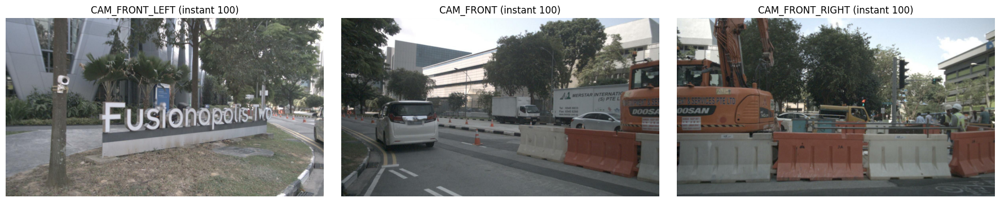

In [10]:
# Converted scene-0061 (copied from the training version): content and a look at the 3 front cameras
import glob
import matplotlib.pyplot as plt
from PIL import Image

!ls {OUT}
!ls {OUT}/images | wc -l
!du -sh {OUT}

t = 100                                    # an instant in the middle of the scene (10 instants per second)
fig, axes = plt.subplots(1, 3, figsize=(18, 3.5))
for ax, cam, name in zip(axes, [1, 0, 2], ['CAM_FRONT_LEFT', 'CAM_FRONT', 'CAM_FRONT_RIGHT']):
    ax.imshow(Image.open(f'{OUT}/images/{t:03d}_{cam}.jpg')); ax.set_title(f'{name} (instant {t})'); ax.axis('off')
plt.tight_layout(); plt.show()

In [11]:
!{PY} --version  # a last check of Python version on the env, should be 3.9

Python 3.9.23


## 3. Mask the sky

The sky is located at infinity, 3D Gaussian splats cannot model infinite depth without creating "floaters" or expanding excessively in size. A mask allows these pixels to be excluded from the scene's 3D geometry, enabling the sky to be modeled separately (via a distant environment model or skydome) and preventing the corruption of photometric and depth-related loss calculations.

I use SegFormer-B5 a multiclassifier deeplearning model who mask road, sky, signalisation, human etc... The ID 10 is for the sky class, so the mask i'm using here is about to show all sky pixels in white color and others in black.

In [ ]:
# # Sky masks with SegFormer-B5 (Cityscapes) from Hugging Face: the same model as DriveStudio's tool,
# # run in Kaggle's own Python (recent PyTorch), not in the Python 3.9 environment.
# import os, glob, numpy as np, torch
# from PIL import Image
# from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation

# OUT = '/kaggle/working/drivestudio/data/nuscenes/processed_10Hz/mini/000'
# SKY_DIR = f'{OUT}/sky_masks'    # to save the generated masks
# os.makedirs(SKY_DIR, exist_ok=True)  # to create the dir if it doesn't exist

# name = 'nvidia/segformer-b5-finetuned-cityscapes-1024-1024'  # ID of the model Segformer finturned on cityscapes with the resolution 1024-1024
# processor = SegformerImageProcessor.from_pretrained(name)
# model = SegformerForSemanticSegmentation.from_pretrained(name).cuda().eval().half()
# SKY = [i for i, lab in model.config.id2label.items() if lab == 'sky'][0]   # = ID 10 in Cityscapes
# print('sky class id:', SKY)

# images = sorted(glob.glob(f'{OUT}/images/*')) # dir of every image_file in OUT/images/
# for path in images:
#     out_path = f'{SKY_DIR}/{os.path.splitext(os.path.basename(path))[0]}.png'
#     if os.path.exists(out_path):
#         continue                                            # already done
#     img = Image.open(path).convert('RGB')
#     inputs = processor(images=img, return_tensors='pt')['pixel_values'].cuda().half()
#     with torch.no_grad():
#         logits = model(pixel_values=inputs).logits          # low-resolution class scores
#         logits = torch.nn.functional.interpolate(logits.float(), size=img.size[::-1],
#                                                  mode='bilinear', align_corners=False)
#     sky = (logits.argmax(1)[0] == SKY).cpu().numpy()
#     Image.fromarray((sky * 255).astype(np.uint8)).save(out_path)   # white = sky

# print(len(os.listdir(SKY_DIR)), 'sky masks for', len(images), 'images')

In [12]:
# Sky masks were computed in the training version (SegFormer-B5, Cityscapes, class 10 = sky)
# and copied with the scene: here we only check them.
import os, glob
SKY_DIR = f'{OUT}/sky_masks'
images = sorted(glob.glob(f'{OUT}/images/*'))
print(len(os.listdir(SKY_DIR)), 'sky masks for', len(images), 'images')   # the two numbers must match

1146 sky masks for 1146 images


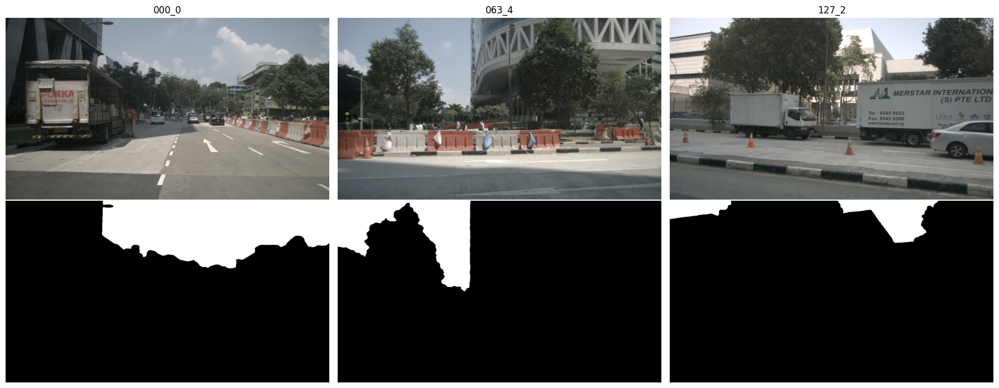

In [13]:
# A few images with their sky mask: the white area must cover the sky only
import matplotlib.pyplot as plt
picks = images[::len(images) // 3][:3] # 3 images 
fig, axes = plt.subplots(2, 3, figsize=(18, 7))
for col, path in enumerate(picks):
    base = os.path.splitext(os.path.basename(path))[0]
    axes[0, col].imshow(Image.open(path)); axes[0, col].set_title(base)
    axes[1, col].imshow(Image.open(f'{SKY_DIR}/{base}.png'), cmap='gray')
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout(); plt.show()

## 4.SMPL : Skinned Multi-Person Linear Model

What and why use SMPL in OmniRe ?

Unlike rigid objects (vehicles, street signs) whose motion reduces to a simple $SE(3)$ transformation matrix, a pedestrian deforms non-rigidly with every stride (leg articulation, swinging arms).

* **Geometric Anchors for 3D Gaussians**: Instead of optimizing free Gaussians that would easily diverge or produce floating artifacts during non-rigid motion, OmniRe binds the 3D Gaussians directly to the surface of the pedestrian's SMPL mesh.
* **Temporally Coherent Deformation**: As the pose parameters $\vec{\theta}_t$ evolve over time, the attached Gaussians follow the forward kinematics of the underlying SMPL skeletal rig.
* **Editing and Re-animation**: Pedestrians can be re-posed or animated along entirely new trajectories simply by swapping or modifying $\vec{\theta}$, preserving geometric consistency and surface texture.

In [ ]:
# # Preprocessed pedestrian poses for nuScenes mini, provided by the DriveStudio authors
# DS = '/kaggle/working/drivestudio'
# !pip install -q gdown                # gdown downloads files from Google Drive
# !cd {DS}/data && gdown 1Z0gJVRtPnjvusQVaW7ghZnwfycZStCZx && unzip -q -o nuscenes_processed_humanpose.zip && rm nuscenes_processed_humanpose.zip
# !find {DS}/data -name "smpl.pkl" | head -3

In [14]:
# Pedestrian poses (provided by the DriveStudio authors) were downloaded in the training version
# and copied with the scene: here we only check them.
!ls -lh {OUT}/humanpose/

total 3.3M
-rw-r--r-- 1 root root 3.3M Nov  5 15:44 smpl.pkl


In [ ]:
# # SMPL body model where DriveStudio expects it + check the pedestrian poses of our scene
# import os, shutil
# DS = '/kaggle/working/drivestudio'
# os.makedirs(f'{DS}/smpl_models', exist_ok=True)
# import glob
# shutil.copy(glob.glob('/kaggle/input/**/basicmodel_neutral_lbs_10_207_0_v1.1.0.pkl', recursive=True)[0],
#             f'{DS}/smpl_models/SMPL_NEUTRAL.pkl')
# !ls -lh {DS}/smpl_models/
# !ls -lh {DS}/data/nuscenes/processed_10Hz/mini/000/humanpose/

In [15]:
# SMPL body model: already in DriveStudio's folder copied from the training version
!ls -lh {DS}/smpl_models/

total 236M
-rw-r--r-- 1 root root 236M Nov  5 15:47 SMPL_NEUTRAL.pkl


```text
drivestudio/
│
├── smpl_models/
│   └── SMPL_NEUTRAL.pkl
│
└── data/
    └── nuscenes/
        └── processed_10Hz/
            └── mini/
                └── 000/
                    └── humanpose/
                        ├── ...
                        └── smpl.pkl
```

## 5.OmniRe Training

Training runs **in the foreground**: the cell only ends when training is finished, which is required for **Save Version → Save & Run All (Commit)** (a background process would be killed when the notebook ends).

OmniRe on scene-0061, 3 front cameras, every 10th frame held out for testing, 30,000 iterations (DriveStudio defaults). Images are kept in RAM (`preload_device=cpu`) and training runs on GPU 1. At the end, DriveStudio saves `checkpoint_final.pth`, evaluates the test frames and renders videos.

In [ ]:
# # OmniRe training (blocking, ~4 h on a T4). The full log goes to a file; only its end is shown.
# os.makedirs('/kaggle/working/logs', exist_ok=True)
# RUN = '/kaggle/working/ds_output/nuscenes/omnire_scene0061_3cams'
# LOG = '/kaggle/working/logs/omnire.log'
# train = (f'cd {DS} && PYTHONPATH={DS} CUDA_VISIBLE_DEVICES=1 PYTORCH_CUDA_ALLOC_CONF=max_split_size_mb:128 '
#          f'{PY} tools/train.py --config_file configs/omnire.yaml '
#          f'--output_root /kaggle/working/ds_output --project nuscenes --run_name omnire_scene0061_3cams '
#          f'dataset=nuscenes/3cams data.scene_idx=0 data.pixel_source.test_image_stride=10 '
#          f'data.preload_device=cpu > {LOG} 2>&1')
# !{train}
# !tail -n 25 {LOG}
# !ls -lh {RUN}

## 6. Results

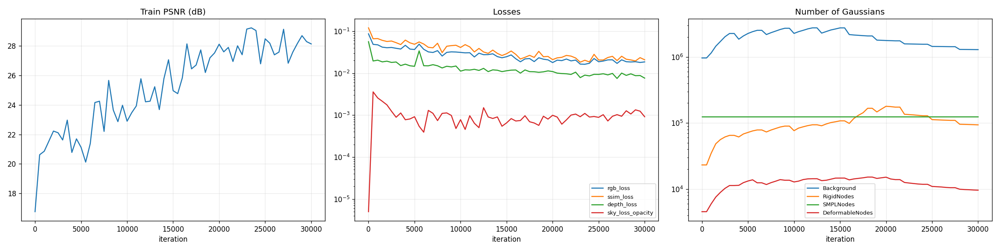

,test
psnr,22.9240
ssim,0.6623
lpips,0.2309
occupied_psnr,22.8639
occupied_ssim,0.6530
masked_psnr,21.1416
masked_ssim,0.5507
human_psnr,21.7531
human_ssim,0.5359
vehicle_psnr,20.5844


test_set_30000_Background_rgbs.mp4	 test_set_30000_rgbs.mp4
test_set_30000_DeformableNodes_rgbs.mp4  test_set_30000_RigidNodes_rgbs.mp4
test_set_30000_Dynamic_rgbs.mp4		 test_set_30000_SMPLNodes_rgbs.mp4
test_set_30000_gt_rgbs.mp4


In [16]:
# Results of the training version (saved in its output): training curves + test metrics
import pandas as pd
from IPython.display import Image as ShowImage, display
display(ShowImage(f'{SRC}/omnire_results/omnire_training_curves.png'))
display(pd.read_csv(f'{SRC}/omnire_results/test_metrics.csv', index_col=0))
!ls {SRC}/ds_output/nuscenes/omnire_scene0061_3cams/videos

In the test, OmniRe achieves ≈ 22.9 dB, compared to ≈ 17.6 dB for splatfacto using 3 cameras from the front view. An improvement of about 5 dB corresponds to an error that is roughly three times smaller. Since the two test protocols are not identical, this should be viewed as an order of magnitude rather than an exact measurement. Moreover, the most striking difference isn't reflected in the numbers: it’s the cars and pedestrians, which appear as distinct, tangible objects instead of mere blurry patches.

In [18]:
%%writefile /kaggle/working/shift_render.py
# Render OmniRe (DriveStudio) from front-camera poses shifted sideways.
# Usage (from the DriveStudio folder, with its Python 3.9 environment):
#   python shift_render.py <run_dir> <out_dir>
import os, sys
import numpy as np
import torch
import imageio
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from omegaconf import OmegaConf
from datasets.driving_dataset import DrivingDataset
from datasets.base.pixel_source import get_rays
from utils.misc import import_str

RUN, OUT = sys.argv[1], sys.argv[2]
SHIFTS = [-3, -2, -1, 0, 1, 2, 3]          # metres, along the camera's right axis (negative = left)
VIDEO_SHIFTS = [0, -2, 2]                  # shifts shown side by side in the video
os.makedirs(OUT, exist_ok=True)

# 1) Scene data + trained model, exactly as DriveStudio's eval.py does
cfg = OmegaConf.load(os.path.join(RUN, 'config.yaml'))
cfg.data.preload_device = 'cpu'            # images in RAM to save GPU memory
dataset = DrivingDataset(data_cfg=cfg.data)
trainer = import_str(cfg.trainer.type)(
    **cfg.trainer,
    num_timesteps=dataset.num_img_timesteps,
    model_config=cfg.model,
    num_train_images=len(dataset.train_image_set),
    num_full_images=len(dataset.full_image_set),
    test_set_indices=dataset.test_timesteps,
    scene_aabb=dataset.get_aabb().reshape(2, 3),
    device=torch.device('cuda'),
)
trainer.resume_from_checkpoint(ckpt_path=os.path.join(RUN, 'checkpoint_final.pth'), load_only_model=True)
trainer.set_eval()

cam = dataset.pixel_source.camera_data[0]  # CAM_FRONT
T = cam.cam_to_worlds.shape[0]

def render(t, d):
    """Front camera at frame t, moved d metres sideways. Returns (render, real photo)."""
    image_infos, cam_infos = cam.get_image(t)          # true time, image index, intrinsics of frame t
    c2w = cam_infos['camera_to_world'].clone()
    c2w[:3, 3] = c2w[:3, 3] + c2w[:3, 0] * d          # OpenCV camera: column 0 = right direction
    H, W = image_infos['origins'].shape[:2]
    y, x = torch.meshgrid(torch.arange(H), torch.arange(W), indexing='ij')
    o, v, n = get_rays(x.flatten().to(c2w), y.flatten().to(c2w), c2w, cam_infos['intrinsics'])
    image_infos['origins'] = o.reshape(H, W, 3)
    image_infos['viewdirs'] = v.reshape(H, W, 3)
    image_infos['direction_norm'] = n.reshape(H, W, 1)
    cam_infos['camera_to_world'] = c2w
    image_infos = {k: (v.cuda() if torch.is_tensor(v) else v) for k, v in image_infos.items()}
    cam_infos = {k: (v.cuda() if torch.is_tensor(v) else v) for k, v in cam_infos.items()}
    with torch.no_grad():
        out = trainer(image_infos=image_infos, camera_infos=cam_infos, novel_view=True)
    return out['rgb'].clamp(0, 1).cpu().numpy(), image_infos['pixels'].cpu().numpy()

# 2) Grids: start / middle / end of the scene, real photo + every shift
for t in [int(T * 0.1), T // 2, int(T * 0.9)]:
    fig, axes = plt.subplots(1, len(SHIFTS) + 1, figsize=(3.2 * (len(SHIFTS) + 1), 2.2))
    renders = [render(t, d) for d in SHIFTS]
    axes[0].imshow(renders[SHIFTS.index(0)][1]); axes[0].set_title(f'photo (frame {t})', fontsize=8)
    for ax, d, (rgb, _) in zip(axes[1:], SHIFTS, renders):
        ax.imshow(rgb); ax.set_title(f'{d:+d} m', fontsize=8)
    for ax in axes:
        ax.axis('off')
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f'shift_frame{t:03d}.png'), dpi=100); plt.close()
    print('saved grid for frame', t, flush=True)

# 3) Video over the whole scene: 0 m | -2 m | +2 m side by side
writer = imageio.get_writer(os.path.join(OUT, 'shift_video.mp4'), fps=10)
for t in range(T):
    row = np.concatenate([render(t, d)[0] for d in VIDEO_SHIFTS], axis=1)
    writer.append_data((row * 255).astype(np.uint8))
writer.close()
print('saved video', flush=True)

Writing /kaggle/working/shift_render.py


In [19]:
# Render the learned scene from front-camera poses shifted sideways (-3 m ... +3 m)
RUN_IN = f'{SRC}/ds_output/nuscenes/omnire_scene0061_3cams'     # trained model from the training version
!cd {DS} && PYTHONPATH={DS} CUDA_VISIBLE_DEVICES=0 {PY} /kaggle/working/shift_render.py {RUN_IN} /kaggle/working/shifts 2>&1 | tail -n 20

Loading lidar: 100%|██████████| 191/191 [00:01<00:00, 101.17it/s]
Projecting lidar pts on images for camera CAM_FRONT: 100%|██████████| 191/191 [00:13<00:00, 13.88it/s]
Projecting lidar pts on images for camera CAM_FRONT_LEFT: 100%|██████████| 191/191 [00:12<00:00, 14.71it/s]
Projecting lidar pts on images for camera CAM_FRONT_RIGHT: 100%|██████████| 191/191 [00:13<00:00, 14.68it/s]
/tmp/ds_env/lib/python3.9/site-packages/torchmetrics/utilities/imports.py:23: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution
/tmp/ds_env/lib/python3.9/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/tmp/ds

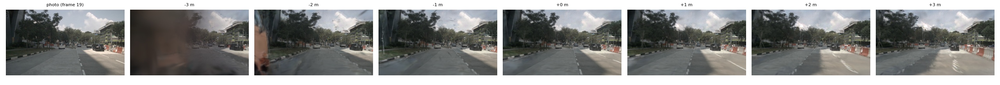

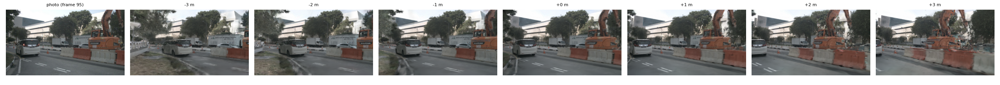

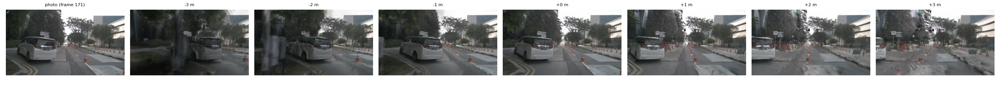

In [24]:
from IPython.display import Image as ShowImage, Video, display
import glob
for png in sorted(glob.glob('/kaggle/working/shifts/shift_frame*.png')):
    display(ShowImage(png))
display(Video('/kaggle/working/shifts/shift_video.mp4', embed=True, width=900))

In [25]:
%%writefile /kaggle/working/rotate_render.py
# Render OmniRe (DriveStudio) from the front camera turned left/right (yaw) and up/down (pitch).
# Usage (from the DriveStudio folder, with its Python 3.9 environment):
#   python rotate_render.py <run_dir> <out_dir>
import os, sys, math
import numpy as np
import torch
import imageio
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from omegaconf import OmegaConf
from datasets.driving_dataset import DrivingDataset
from datasets.base.pixel_source import get_rays
from utils.misc import import_str

RUN, OUT = sys.argv[1], sys.argv[2]
YAWS = [-60, -40, -20, 0, 20, 40, 60]      # degrees: negative = turn left, positive = turn right
PITCHES = [-20, -10, 0, 10, 20]            # degrees: negative = look down, positive = look up
VIDEO_YAWS = [-40, 0, 40]                  # yaws shown side by side in the video
os.makedirs(OUT, exist_ok=True)

# 1) Scene data + trained model, exactly as DriveStudio's eval.py does
cfg = OmegaConf.load(os.path.join(RUN, 'config.yaml'))
cfg.data.preload_device = 'cpu'
dataset = DrivingDataset(data_cfg=cfg.data)
trainer = import_str(cfg.trainer.type)(
    **cfg.trainer,
    num_timesteps=dataset.num_img_timesteps,
    model_config=cfg.model,
    num_train_images=len(dataset.train_image_set),
    num_full_images=len(dataset.full_image_set),
    test_set_indices=dataset.test_timesteps,
    scene_aabb=dataset.get_aabb().reshape(2, 3),
    device=torch.device('cuda'),
)
trainer.resume_from_checkpoint(ckpt_path=os.path.join(RUN, 'checkpoint_final.pth'), load_only_model=True)
trainer.set_eval()

cam = dataset.pixel_source.camera_data[0]  # CAM_FRONT
T = cam.cam_to_worlds.shape[0]

def local_rotation(yaw_deg, pitch_deg):
    """Rotation in the camera's own frame (OpenCV: x right, y down, z forward)."""
    a, b = math.radians(yaw_deg), math.radians(pitch_deg)
    yaw = torch.tensor([[math.cos(a), 0, math.sin(a)],      # around y: forward z turns towards +x (right)
                        [0, 1, 0],
                        [-math.sin(a), 0, math.cos(a)]])
    pitch = torch.tensor([[1, 0, 0],                         # around x: forward z turns towards -y (up)
                          [0, math.cos(b), -math.sin(b)],
                          [0, math.sin(b), math.cos(b)]])
    return yaw @ pitch

def render(t, yaw=0.0, pitch=0.0):
    """Front camera at frame t, same position, turned by yaw / pitch (degrees). Returns (render, photo)."""
    image_infos, cam_infos = cam.get_image(t)
    c2w = cam_infos['camera_to_world'].clone()
    c2w[:3, :3] = c2w[:3, :3] @ local_rotation(yaw, pitch).to(c2w)   # position unchanged
    H, W = image_infos['origins'].shape[:2]
    y, x = torch.meshgrid(torch.arange(H), torch.arange(W), indexing='ij')
    o, v, n = get_rays(x.flatten().to(c2w), y.flatten().to(c2w), c2w, cam_infos['intrinsics'])
    image_infos['origins'] = o.reshape(H, W, 3)
    image_infos['viewdirs'] = v.reshape(H, W, 3)
    image_infos['direction_norm'] = n.reshape(H, W, 1)
    cam_infos['camera_to_world'] = c2w
    image_infos = {k: (v.cuda() if torch.is_tensor(v) else v) for k, v in image_infos.items()}
    cam_infos = {k: (v.cuda() if torch.is_tensor(v) else v) for k, v in cam_infos.items()}
    with torch.no_grad():
        out = trainer(image_infos=image_infos, camera_infos=cam_infos, novel_view=True)
    return out['rgb'].clamp(0, 1).cpu().numpy(), image_infos['pixels'].cpu().numpy()

# 2) Grids: for 3 instants, row 1 = turning left/right, row 2 = looking down/up
for t in [int(T * 0.1), T // 2, int(T * 0.9)]:
    ncol = len(YAWS) + 1
    fig, axes = plt.subplots(2, ncol, figsize=(3.2 * ncol, 4.6))
    yaw_imgs = [render(t, yaw=a) for a in YAWS]
    axes[0, 0].imshow(yaw_imgs[YAWS.index(0)][1]); axes[0, 0].set_title(f'photo (frame {t})', fontsize=8)
    for ax, a, (rgb, _) in zip(axes[0, 1:], YAWS, yaw_imgs):
        ax.imshow(rgb); ax.set_title(f'yaw {a:+d}° ({"left" if a < 0 else "right" if a > 0 else "front"})', fontsize=8)
    for ax, b in zip(axes[1, 1:], PITCHES):
        ax.imshow(render(t, pitch=b)[0]); ax.set_title(f'pitch {b:+d}° ({"down" if b < 0 else "up" if b > 0 else "level"})', fontsize=8)
    for ax in axes.ravel():
        ax.axis('off')
    plt.tight_layout(); plt.savefig(os.path.join(OUT, f'rotate_frame{t:03d}.png'), dpi=100); plt.close()
    print('saved grid for frame', t, flush=True)

# 3) Video over the whole scene: turned left 40° | front | turned right 40°
writer = imageio.get_writer(os.path.join(OUT, 'rotate_video.mp4'), fps=10, macro_block_size=1)
for t in range(T):
    row = np.concatenate([render(t, yaw=a)[0] for a in VIDEO_YAWS], axis=1)
    writer.append_data((row * 255).astype(np.uint8))
writer.close()
print('saved video', flush=True)

Writing /kaggle/working/rotate_render.py


In [26]:
# Render the learned scene with the front camera turned left/right and up/down
RUN_IN = f'{SRC}/ds_output/nuscenes/omnire_scene0061_3cams'
!cd {DS} && PYTHONPATH={DS} CUDA_VISIBLE_DEVICES=0 {PY} /kaggle/working/rotate_render.py {RUN_IN} /kaggle/working/rotations 2>&1 | tail -n 8

  warnings.warn(msg)
/kaggle/working/drivestudio/models/gaussians/basics.py:68: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3571.)
  w1, x1, y1, z1 = q1.T
Using predefined pose: da_pose
saved grid for frame 19
saved grid for frame 95
saved grid for frame 171
saved video


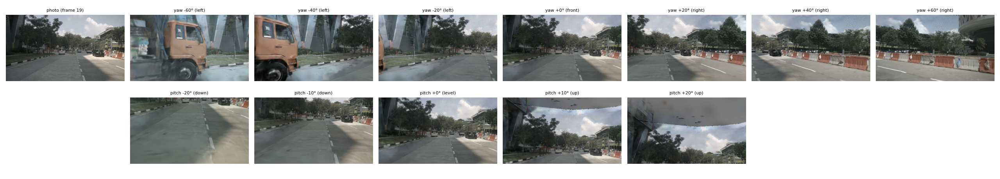

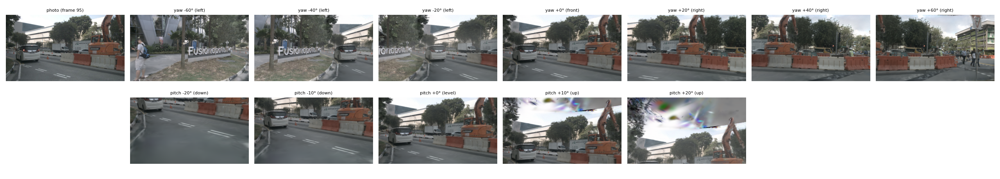

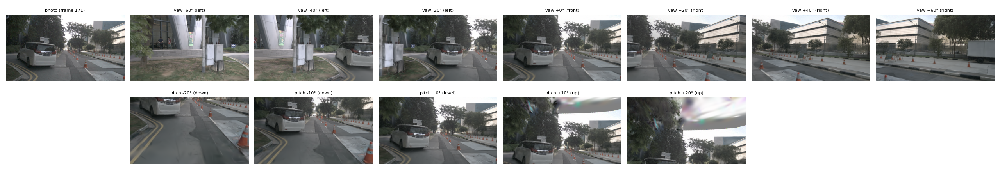

In [29]:
from IPython.display import Image as ShowImage, Video, display
import glob
for png in sorted(glob.glob('/kaggle/working/rotations/rotate_frame*.png')):
    display(ShowImage(png))
display(Video('/kaggle/working/rotations/rotate_video.mp4', embed=True, width=900))

# results